In [25]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

## Data Collection

In [5]:
funds = ["FSPTX", "FSELX", "FSCSX", "FSPHX", "FBIOX", "FSMEX", "FPHAX", "FIDSX", "FSRBX", "FSPCX", "FSENX", "FSDAX", "FSRFX", "FSCPX", "FSAVX", "FSRPX", "FDFAX", "FSTCX", "FWRLX"]
prices = yf.download(tickers=funds + ["SPY", "XLK"], start="2015-01-01", end="2026-10-01", auto_adjust=False, progress=False)

In [6]:
prices = prices["Adj Close"]
prices

Ticker,FBIOX,FDFAX,FIDSX,FPHAX,FSAVX,FSCPX,FSCSX,FSDAX,FSELX,FSENX,...,FSPCX,FSPHX,FSPTX,FSRBX,FSRFX,FSRPX,FSTCX,FWRLX,SPY,XLK
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,11.000014,46.551399,4.670525,10.712301,20.123484,19.435740,4.505634,6.041415,2.884584,36.330261,...,26.004522,10.029356,4.799391,11.604661,42.423233,4.205565,28.825602,3.914888,169.267502,18.041683
2015-01-05,11.020169,46.056793,4.580222,10.622029,19.604450,19.080353,4.434748,5.946351,2.837291,34.780518,...,25.517300,9.970015,4.720869,11.296418,41.462181,4.124608,28.381540,3.837536,166.210541,17.766272
2015-01-06,10.810784,45.965549,4.512496,10.556832,19.371323,18.899740,4.365809,5.905756,2.785574,34.280083,...,25.207952,9.872950,4.676363,11.035933,40.682724,4.080832,28.109367,3.798860,164.645081,17.552063
2015-01-07,11.174009,46.618633,4.551346,10.757439,19.718809,19.243483,4.386452,5.963821,2.811093,34.280083,...,25.455431,10.130101,4.708274,11.118417,40.833302,4.156613,28.276485,3.833239,166.696701,17.700695
2015-01-08,11.334733,47.358150,4.610148,10.963058,20.066299,19.523130,4.462013,6.089202,2.889349,35.038815,...,25.803450,10.312268,4.812407,11.292076,41.719051,4.208390,28.682350,3.893402,169.654785,18.089767
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-24,29.000000,91.109657,16.469999,34.869999,51.939999,61.090000,24.660000,25.860001,63.730000,90.510002,...,91.459999,29.990000,58.070000,36.110001,112.410004,16.629999,67.925964,15.230000,767.179993,194.710007
2026-09-25,28.920000,91.507607,16.610001,35.000000,52.450001,61.259998,24.530001,26.059999,64.379997,89.889999,...,91.919998,29.959999,58.459999,36.509998,113.059998,16.719999,67.727005,15.320000,771.349976,196.270004
2026-09-28,28.969999,91.855804,16.410000,34.990002,51.380001,60.459999,24.299999,25.490000,63.840000,89.889999,...,91.730003,30.139999,57.889999,36.000000,112.720001,16.680000,66.851562,15.060000,765.609985,194.529999


In [7]:
log_returns = np.log(prices).diff().dropna()
market_log_returns = log_returns["SPY"]
xlk_log_returns = log_returns["XLK"]
print(log_returns)

Ticker         FBIOX     FDFAX     FIDSX     FPHAX     FSAVX     FSCPX  \
Date                                                                     
2015-01-05  0.001831 -0.010682 -0.019524 -0.008463 -0.026131 -0.018454   
2015-01-06 -0.019183 -0.001983 -0.014897 -0.006157 -0.011963 -0.009511   
2015-01-07  0.033046  0.014108  0.008573  0.018824  0.017779  0.018024   
2015-01-08  0.014281  0.015739  0.012837  0.018934  0.017469  0.014428   
2015-01-09  0.000434 -0.005491 -0.011914 -0.003208 -0.013017 -0.008090   
...              ...       ...       ...       ...       ...       ...   
2026-09-24  0.004839 -0.008373 -0.003031  0.011537 -0.012627 -0.004573   
2026-09-25 -0.002762  0.004358  0.008464  0.003721  0.009771  0.002779   
2026-09-28  0.001727  0.003798 -0.012114 -0.000286 -0.020611 -0.013145   
2026-09-29 -0.003112 -0.006302 -0.004275 -0.004583 -0.000389  0.000827   
2026-09-30 -0.001733 -0.014602 -0.011696 -0.013877 -0.014118 -0.001985   

Ticker         FSCSX     FSDAX     FS

## Performace Summary

### Part 1

In [8]:
mean_returns = log_returns.mean() * 252
volatilities = log_returns.std() * np.sqrt(252)
sharpe_ratio = mean_returns / volatilities

absolute = pd.DataFrame({
    "Mean Return": mean_returns,
    "Volatility": volatilities,
    "Sharpe Ratio": sharpe_ratio,
})

summary_abs = absolute.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary_abs.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
summary_abs.round(4)

,Mean Return,Volatility,Sharpe Ratio
Min,0.0562,0.1482,0.2480
Q1,0.0829,0.1913,0.3851
Mean,0.1171,0.2246,0.5209
Median,0.1048,0.2181,0.5156
Q3,0.1223,0.2403,0.6165
Max,0.2653,0.3431,0.8469


### Part 2

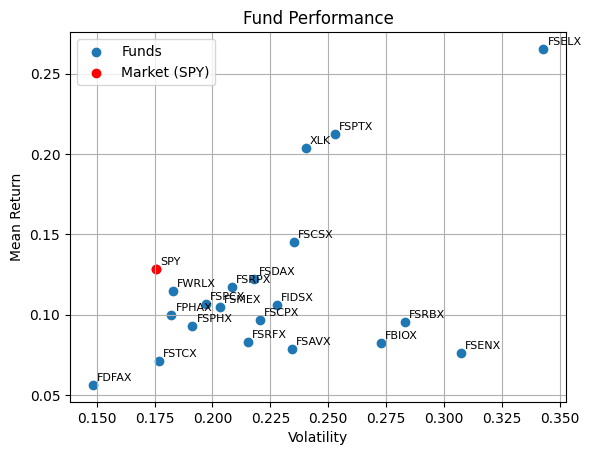

0.7313612772108294


,Mean Return,Volatility,Sharpe Ratio
Ticker,,,
FSCSX,0.144971,0.235144,0.616521
FSELX,0.265296,0.343075,0.773289
FSPTX,0.212654,0.253010,0.840498
XLK,0.203525,0.240315,0.846909


In [9]:
market_mean_return = market_log_returns.mean() * 252
market_volatility = market_log_returns.std() * np.sqrt(252)

fund_metrics = pd.DataFrame({
    "Mean Return": mean_returns,
    "Volatility": volatilities,
})
plt.scatter(fund_metrics["Volatility"], fund_metrics["Mean Return"], label="Funds")
for t in fund_metrics.index:
    plt.annotate(t, (fund_metrics.loc[t, "Volatility"], fund_metrics.loc[t, "Mean Return"]),
                 fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.scatter(market_volatility, market_mean_return, color="red", marker="o", label="Market (SPY)")
plt.xlabel("Volatility")
plt.ylabel("Mean Return")
plt.title("Fund Performance")
plt.grid(True)
plt.legend()
plt.show()

indices = fund_metrics["Mean Return"] > market_mean_return
outperforms_market = fund_metrics[indices].copy()
outperforms_market

market_sharpe_ratio = market_mean_return / market_volatility
print(market_sharpe_ratio)
outperforms_market["Sharpe Ratio"] = outperforms_market["Mean Return"] / outperforms_market["Volatility"]
outperforms_market

Only the three technology-oriented funds, Software (FSCSX, 14.5%), Technology (FSPTX, 21.3%) and Semiconductors (FSLX, 26.5%), outperform SPY's 12.9% mean return, but each does so with higher volatility (23.5%-34.3% vs. 17.6% for SPY).

### Part 3

#### (a)

In [10]:
combined = log_returns.copy()
combined["SPY"] = market_log_returns
covariances = combined.cov() * 252
betas = (covariances["SPY"] / covariances.loc["SPY", "SPY"]).drop("SPY")

alphas = mean_returns - betas * market_mean_return
alphas

treynor = (mean_returns) / betas
treynor

tracking_error = log_returns.sub(market_log_returns, axis=0)
tracking_error = tracking_error.std() * np.sqrt(252)

information_ratio = (mean_returns - market_mean_return) / tracking_error
information_ratio

relative = pd.DataFrame({
    "Jensen's Alpha": alphas,
    "Beta": betas,
    "Treynor Ratio": treynor,
    "Tracking Error": tracking_error,
    "Information Ratio": information_ratio,
})

summary = relative.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
summary

,Jensen's Alpha,Beta,Treynor Ratio,Tracking Error,Information Ratio
Min,-0.062318,0.595044,0.071747,0.000000,-0.569804
Q1,-0.045766,0.892899,0.085762,0.122627,-0.293600
Mean,-0.013311,1.010045,0.112978,0.135850,-0.092200
Median,-0.014821,1.009317,0.112372,0.127063,-0.178788
Q3,-0.000681,1.121156,0.127883,0.139700,-0.091357
Max,0.064266,1.564427,0.169580,0.248289,0.716025


(b)

In [11]:
area = pd.Series({
    "FSPTX": "Technology", "FSELX": "Semiconductors", "FSCSX": "Software",
    "FSPHX": "Health Care", "FBIOX": "Biotechnology", "FSMEX": "Medical Technology",
    "FPHAX": "Pharmaceuticals", "FIDSX": "Financials", "FSRBX": "Banking",
    "FSPCX": "Insurance", "FSENX": "Energy", "FSDAX": "Aerospace/Defense",
    "FSRFX": "Transportation", "FSCPX": "Consumer Discretionary", "FSAVX": "Automotive",
    "FSRPX": "Retailing", "FDFAX": "Consumer Staples", "FSTCX": "Telecommunications",
    "FWRLX": "Wireless",
})

top5 = alphas.sort_values(ascending=False).index[:5]
top5_table = pd.concat([area[top5].rename("Area"), relative.loc[top5, ["Jensen's Alpha", "Beta"]], absolute.loc[top5]], axis=1)
top5_table["Mean Return Rank"] = mean_returns.rank(ascending=False)[top5].astype(int)
top5_table["Sharpe Rank"] = sharpe_ratio.rank(ascending=False)[top5].astype(int)
top5_table.round(4)

KeyError: "['XLK'] not in index"

### 4.

#### (a)

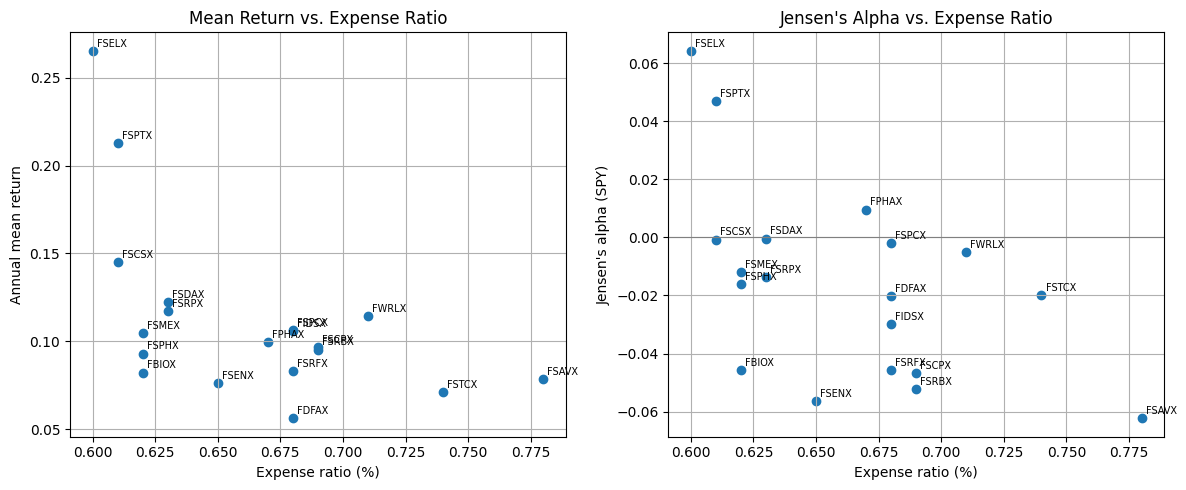

In [ ]:
expense = pd.Series({
    "FSPTX": 0.61, "FSELX": 0.60, "FSCSX": 0.61, "FSPHX": 0.62, "FBIOX": 0.62,
    "FSMEX": 0.62, "FPHAX": 0.67, "FIDSX": 0.68, "FSRBX": 0.69, "FSPCX": 0.68,
    "FSENX": 0.65, "FSDAX": 0.63, "FSRFX": 0.68, "FSCPX": 0.69, "FSAVX": 0.78,
    "FSRPX": 0.63, "FDFAX": 0.68, "FSTCX": 0.74, "FWRLX": 0.71,
})

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(expense[funds], mean_returns[funds])
ax[0].set_xlabel("Expense ratio (%)")
ax[0].set_ylabel("Annual mean return")
ax[0].set_title("Mean Return vs. Expense Ratio")
ax[0].grid(True)

ax[1].scatter(expense[funds], alphas[funds])
ax[1].axhline(0, color="gray", linewidth=0.8)
ax[1].set_xlabel("Expense ratio (%)")
ax[1].set_ylabel("Jensen's alpha (SPY)")
ax[1].set_title("Jensen's Alpha vs. Expense Ratio")
ax[1].grid(True)

for t in funds:
    ax[0].annotate(t, (expense[t], mean_returns[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax[1].annotate(t, (expense[t], alphas[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")

plt.tight_layout()
plt.savefig("fig_1_4.png", dpi=300)
plt.show()

#### (b)

In [ ]:
print("Corr(ER, Mean): ", round(expense[funds].corr(mean_returns[funds]), 4))
print("Corr(ER, Alpha):", round(expense[funds].corr(alphas[funds]), 4))

Corr(ER, Mean):  -0.5501
Corr(ER, Alpha): -0.5391


### 5.

#### (a)

In [ ]:
xlk_mean_return = xlk_log_returns.mean() * 252

returns_xlk = log_returns[funds].copy()
returns_xlk["XLK"] = xlk_log_returns
cov_xlk = returns_xlk.cov() * 252
betas_xlk = (cov_xlk["XLK"] / cov_xlk.loc["XLK", "XLK"]).drop("XLK")

alphas_xlk = mean_returns - betas_xlk * xlk_mean_return
treynor_xlk = mean_returns / betas_xlk
tracking_error_xlk = log_returns[funds].sub(xlk_log_returns, axis=0).std() * np.sqrt(252)
information_ratio_xlk = (mean_returns - xlk_mean_return) / tracking_error_xlk

relative_xlk = pd.DataFrame({
    "Jensen's Alpha": alphas_xlk,
    "Beta": betas_xlk,
    "Treynor Ratio": treynor_xlk,
    "Tracking Error": tracking_error_xlk,
    "Information Ratio": information_ratio_xlk,
})
summary_xlk = relative_xlk.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary_xlk.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
display(summary_xlk.round(4))

,Jensen's Alpha,Beta,Treynor Ratio,Tracking Error,Information Ratio
Min,-0.0647,0.3177,0.1117,0.0596,-0.7486
Q1,-0.0329,0.5456,0.1466,0.1627,-0.6535
Mean,-0.0194,0.6449,0.1736,0.1845,-0.4806
Median,-0.0168,0.6089,0.1731,0.1838,-0.5125
Q3,-0.0020,0.6858,0.1934,0.2063,-0.4414
Max,0.0166,1.2688,0.2411,0.2976,0.3633


#### (b)

In [ ]:
compare = pd.DataFrame({
    "Alpha_SPY": alphas[funds],
    "Rank_SPY": alphas[funds].rank(ascending=False).astype(int),
    "Alpha_XLK": alphas_xlk,
    "Rank_XLK": alphas_xlk.rank(ascending=False).astype(int),
}).sort_values("Rank_SPY")
display(compare.round(4))

,Alpha_SPY,Rank_SPY,Alpha_XLK,Rank_XLK
Ticker,,,,
FSELX,0.0643,1,0.0071,3
FSPTX,0.0469,2,0.0044,5
FPHAX,0.0096,3,0.0134,2
FSDAX,-0.0004,4,0.0061,4
FSCSX,-0.0008,5,-0.0292,13
FSPCX,-0.0020,6,0.0166,1
FWRLX,-0.0051,7,-0.0201,12
FSMEX,-0.0118,8,-0.0162,9
FSRPX,-0.0136,9,-0.0186,11


### Mean-Variance Efficient Frontier

#### 1. Monthly Data and Split

In [20]:
tickers_2 = ["FSPTX","FIDSX","FSCPX"]
prices_2 = yf.download(tickers=tickers_2, start="2015-01-01", end="2026-10-01", interval ="1mo", auto_adjust=False, progress=False)["Adj Close"][tickers_2]

log_returns_2 = np.log(prices_2).diff().dropna()

half = len(log_returns_2) // 2
r1 = log_returns_2.iloc[:half]
r2 = log_returns_2.iloc[half:]
print(len(r1), r1.index[0],r1.index[-1])
print(len(r2), r2.index[0],r2.index[-1])
returns_1 = r1
returns_2 = r2
print(returns_1)
print(returns_2)

70 2015-02-01 00:00:00 2020-11-01 00:00:00
70 2020-12-01 00:00:00 2026-09-01 00:00:00
Ticker         FSPTX     FIDSX     FSCPX
Date                                    
2015-02-01  0.068048  0.062110  0.077279
2015-03-01 -0.002817  0.000000 -0.004837
2015-04-01  0.012982  0.002024 -0.008784
2015-05-01  0.030155  0.014055  0.005568
2015-06-01 -0.027835 -0.009683  0.015081
...              ...       ...       ...
2020-07-01  0.071444  0.007547  0.065053
2020-08-01  0.116707  0.032062  0.086996
2020-09-01 -0.032826 -0.040872 -0.015778
2020-10-01 -0.038553  0.027433 -0.032146
2020-11-01  0.120733  0.162027  0.110556

[70 rows x 3 columns]
Ticker         FSPTX     FIDSX     FSCPX
Date                                    
2020-12-01  0.066881  0.078762  0.057194
2021-01-01  0.005197 -0.010875 -0.001814
2021-02-01  0.018342  0.112689  0.028789
2021-03-01 -0.001091  0.066147  0.034254
2021-04-01  0.031295  0.063721  0.065543
...              ...       ...       ...
2026-05-01  0.168246 -0.019343

#### 2. Mean Vectors

In [15]:
mu1 = r1.mean()
mu2 = r2.mean()
pd.DataFrame({"mu1": [mu1], "mu2": [mu2]}).round(4)

,mu1,mu2
0,Ticker FSPTX 0.019254 FIDSX 0.006254 FSC...,Ticker FSPTX 0.016509 FIDSX 0.012376 FSC...


#### 3. Covariance Matrices

In [24]:
sigma1 = r1.std()
sigma2 = r2.std()
cov1 = r1.cov()
cov2 = r2.cov()
print("Standard Deviation (Period 1):", sigma1)
print("Standard Deviation (Period 2):", sigma2)
print("Covariance (Period 1):")
display(cov1.round(5))
print("Covariance (Period 2):")
display(cov2.round(5))
print("Variance (Period 1):")
print(np.diag(cov1))
print("Variance (Period 2):")
print(np.diag(cov2))
cov_FSPTX_FIDSX = cov1.values[0,1]
print("Covariance between FSPTX and FIDSX (Period 1):", cov_FSPTX_FIDSX)
cov_FSPTX_FIDSX_2 = cov2.values[0,1]
print("Covariance between FSPTX and FIDSX (Period 2):", cov_FSPTX_FIDSX_2)
cov_FSPTX_FSCPX = cov1.values[0,2]
print("Covariance between FSPTX and FSCPX (Period 1):", cov_FSPTX_FSCPX)
cov_FSPTX_FSCPX_2 = cov2.values[0,2]
print("Covariance between FSPTX and FSCPX (Period 2):", cov_FSPTX_FSCPX_2)
cov_FIDSX_FSCPX = cov1.values[1,2]
print("Covariance between FIDSX and FSCPX (Period 1):", cov_FIDSX_FSCPX)
cov_FIDSX_FSCPX_2 = cov2.values[1,2]
print("Covariance between FIDSX and FSCPX (Period 2):", cov_FIDSX_FSCPX_2)


Standard Deviation (Period 1): Ticker
FSPTX    0.055841
FIDSX    0.060870
FSCPX    0.051879
dtype: float64
Standard Deviation (Period 2): Ticker
FSPTX    0.068836
FIDSX    0.056209
FSCPX    0.061107
dtype: float64
Covariance (Period 1):


Ticker,FSPTX,FIDSX,FSCPX
Ticker,,,
FSPTX,0.00312,0.00237,0.00248
FIDSX,0.00237,0.00371,0.00258
FSCPX,0.00248,0.00258,0.00269


Covariance (Period 2):


Ticker,FSPTX,FIDSX,FSCPX
Ticker,,,
FSPTX,0.00474,0.00156,0.00330
FIDSX,0.00156,0.00316,0.00218
FSCPX,0.00330,0.00218,0.00373


Variance (Period 1):
[0.00311822 0.00370512 0.00269146]
Variance (Period 2):
[0.00473846 0.00315943 0.00373408]
Covariance between FSPTX and FIDSX (Period 1): 0.002367676348663075
Covariance between FSPTX and FIDSX (Period 2): 0.0015627554216367718
Covariance between FSPTX and FSCPX (Period 1): 0.0024811037472741745
Covariance between FSPTX and FSCPX (Period 2): 0.00329953331763787
Covariance between FIDSX and FSCPX (Period 1): 0.0025821573708115133
Covariance between FIDSX and FSCPX (Period 2): 0.0021807828705273286


#### 4. The Two Funds

In [29]:
def two_funds(mu, Sigma):
    inv = np.linalg.inv(Sigma)
    ones = np.ones(len(mu))
    w0 = inv @ ones / (ones @ inv @ ones) #GMV portfolio weights
    w1 = inv @ mu - (ones @ inv @ mu) * w0
    return w0, w1

def mv_port(A, mu, sigma):
    w0, w1 = two_funds(mu, sigma)
    w = w0 + 1/A * w1
    return w

A_grid = np.arange(1, 101)
print(A_grid)

w0_1, w1_1 = two_funds(mu1.values, cov1.values)
w0_2, w1_2 = two_funds(mu2.values, cov2.values)

pd.DataFrame({"w0 (P1)": w0_1, "w1 (P1)": w1_1, "w0 (P2)": w0_2, "w1 (P2)": w1_2})

[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100]


,w0 (P1),w1 (P1),w0 (P2),w1 (P2)
0,0.248650,9.156072,0.294117,6.449334
1,0.089532,-4.208075,0.634794,3.363431
2,0.661818,-4.947998,0.071089,-9.812765
